# H5 waterfall: dữ liệu đêm, dữ liệu ngày và trừ nền median

Notebook dùng với **VS Code + Python + Jupyter**, không cần PyQt.

- **File 1:** quan sát ban đêm, dùng toàn bộ khoảng thời gian trong file làm nền.
- **File 2:** quan sát ban ngày, cần xem mức tăng/giảm so với nền đêm.
- Đại lượng: \(A(t,f)=|S12|=\sqrt{\mathrm{Re}^2+\mathrm{Im}^2}\), theo đơn vị lưu trong H5.
- Nền: \(B_{\rm dB}(f)=\operatorname{median}_t[10\log_{10}(A_1(t,f)+\epsilon)]\).
- Kết quả: \(R_{\rm dB}(t,f)=10\log_{10}(A_2(t,f)+\epsilon)-B_{\rm dB}(f)\).

Median được tính **sau khi đổi sang dB**, không dùng mean hoặc trọng số FFT. Bản signed giữ phần dư âm; bản clipped chỉ cắt khi vẽ màu. **0 dB tương đối = bằng nền đêm**, không phải không có công suất. Đây là so sánh biên độ, không phải phép trừ S12 phức hay chứng nhận đã loại RFI.

## Chạy trong VS Code

1. Cài extensions **Python** và **Jupyter**; chọn Python kernel ở góc phải notebook.
2. Trong terminal của môi trường đó, chạy:
   ```bash
   python -m pip install numpy h5py matplotlib ipykernel
   ```
   Hoặc chạy `%pip install numpy h5py matplotlib ipykernel` trong một cell của kernel đang chọn.
3. Đặt hai H5 cùng thư mục làm việc, hoặc sửa `DATA_DIR`/hai đường dẫn ở cell dưới. Trên Windows có thể dùng `Path(r"C:\Users\Ten\Documents\data")`.
4. Bấm **Run All**. Notebook chỉ đọc hai H5, không ghi đè dữ liệu.

Các output đính kèm trong notebook được tạo từ cặp file 02:15 và 10:15 ngày 24/10/2026 đã cung cấp. Khi đổi file, chạy lại toàn bộ notebook.


## Chỉnh thang màu như ảnh viewer

Sửa `RAW_VMIN_DB = 18`, `RAW_VMAX_DB = 40` và `WATERFALL_CMAP = "inferno"` ở cell cấu hình, rồi chạy lại các cell vẽ. Hai ảnh gốc dùng chung thang cố định. Phần dư mặc định −12..12 dB (signed) hoặc 0..12 dB (clipped), có biến riêng để thay đổi. Không dùng 18..40 dB của phổ gốc làm mặc định cho phần dư tương đối.

Giới hạn màu chỉ đổi cách tô màu: giá trị vượt giới hạn bão hòa ở hai đầu, không sửa dữ liệu hay phép trừ nền. Bản clipped vẫn giữ mảng `residual_db` có dấu riêng.


In [49]:
from pathlib import Path
from datetime import datetime, timezone, timedelta
import warnings
import numpy as np
import h5py
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import TwoSlopeNorm

# SỬA TẠI ĐÂY. DATA_DIR là thư mục chứa hai H5 trên máy bạn.
DATA_DIR = Path(r"C:\Users\Tuch\Documents\VGU\Thesis\Storage\2026-10-24")
FILE_1 = DATA_DIR / "2026-10-24_02-15-09_UTC+0700_13731914092555676744_51.h5"  # nền đêm
FILE_2 = DATA_DIR / "2026-10-24_10-15-46_UTC+0700_13731914092555676744_83.h5"   # ban ngày

EPSILON_LINEAR = 1e-12  # đơn vị giống |S12|; ảnh thuật toán không chỉ định epsilon
DISPLAY_TIMEZONE = timezone(timedelta(hours=7))
# None: hiện toàn dải. Ví dụ (38.7, 39.2) để zoom tần số; không đổi miền tính nền.
DISPLAY_FREQ_MHZ = None
# THANG MÀU: giống trục colorbar trong ảnh viewer, chỉnh tại đây.
WATERFALL_CMAP = "inferno"
RAW_VMIN_DB, RAW_VMAX_DB = 18., 40.        # hai waterfall gốc
SIGNED_VMIN_DB, SIGNED_VMAX_DB = -12., 40. # phần dư giữ dấu
RESIDUAL_VMIN_DB, RESIDUAL_VMAX_DB = 0., 40. # phần dư cắt âm để vẽ
for lower, upper in ((RAW_VMIN_DB, RAW_VMAX_DB), (SIGNED_VMIN_DB, SIGNED_VMAX_DB),
                     (RESIDUAL_VMIN_DB, RESIDUAL_VMAX_DB)):
    if not np.isfinite(lower + upper) or upper <= lower:
        raise ValueError("Giới hạn màu phải hữu hạn và min < max.")
SAVE_PNG = False
PNG_PATH = DATA_DIR / "waterfall_night_median_comparison.png"

for path in (FILE_1, FILE_2):
    if not path.is_file():
        raise FileNotFoundError(f"Không tìm thấy {path.resolve()}. Sửa DATA_DIR hoặc đường dẫn FILE_1/FILE_2.")
assert np.isfinite(EPSILON_LINEAR) and EPSILON_LINEAR > 0
print("File 1 (nền):", FILE_1.resolve())
print("File 2 (đích):", FILE_2.resolve())


File 1 (nền): C:\Users\Tuch\Documents\VGU\Thesis\Storage\2026-10-24\2026-10-24_02-15-09_UTC+0700_13731914092555676744_51.h5
File 2 (đích): C:\Users\Tuch\Documents\VGU\Thesis\Storage\2026-10-24\2026-10-24_10-15-46_UTC+0700_13731914092555676744_83.h5


## Đọc schema H5 gốc

Đọc `/data/s12_real`, `/data/s12_imag`, S11/S22 và thời gian UTC đã lưu. Loại mẫu thiếu/không hữu hạn, S11/S22 không dương hoặc coherence vượt 1 quá sai số cho phép 1e−5. Không dùng coherence cao làm bằng chứng RFI; không dùng ngưỡng hiển thị phase để lọc nền.

Dữ liệu đọc theo block; kết quả biên độ được giữ trong RAM cho notebook. Số ô tối đa có chặn để tránh vô tình đọc một file quá lớn. Không gộp tần số, không nội suy. Các khoảng đứt thời gian được vẽ thành segment riêng. Thời gian H5 của cặp file này là UTC ước lượng, không phải mốc thời gian phần cứng đã xác nhận.


In [50]:
EXPECTED_UNITS = "ADC-count^2 per input FFT bin (mean after frequency grouping)"

def decode_text(value):
    return value.decode("utf-8") if isinstance(value, bytes) else str(value)

def read_observation(path, max_cells=20_000_000, block_rows=256):
    with h5py.File(path, "r") as h:
        meta = dict(h["metadata"].attrs)
        if int(meta.get("data_schema_version", -1)) != 1:
            raise ValueError(f"{path.name}: cần H5 schema 1.")
        if decode_text(meta.get("units", "")) != EXPECTED_UNITS:
            raise ValueError(f"{path.name}: đơn vị chưa được hỗ trợ.")
        frequency = np.asarray(h["frequency_hz"][:], dtype=np.float64)
        if (frequency.ndim != 1 or len(frequency) < 2
                or not np.isfinite(frequency).all() or not (np.diff(frequency) > 0).all()):
            raise ValueError("Trục tần số phải hữu hạn, tăng dần, ít nhất 2 bin.")
        bandwidth = float(meta["frequency_bin_bandwidth_hz"])
        if not np.isfinite(bandwidth) or bandwidth <= 0 or not np.allclose(np.diff(frequency), bandwidth, rtol=1e-8, atol=1e-4):
            raise ValueError("Notebook này cần trục tần số đều như schema viewer.")
        d = h["data"]
        shape = d["s12_real"].shape
        if len(shape) != 2 or shape[1] != len(frequency) or shape[0] == 0:
            raise ValueError("Dạng phổ H5 không hợp lệ.")
        if np.prod(shape) > max_cells:
            raise ValueError("File quá lớn cho giới hạn RAM của notebook. Chọn file nhỏ hơn hoặc chủ động tăng max_cells.")
        names = ("s11_linear", "s22_linear", "s12_real", "s12_imag")
        if any(d[name].shape != shape or d[name].dtype.kind != "f" for name in names):
            raise ValueError("Các thống kê S11/S22/Re/Im phải cùng shape và có kiểu float.")
        starts = np.asarray(d["start_utc_us"][:], dtype=np.float64) / 1e6
        ends = np.asarray(d["end_utc_us"][:], dtype=np.float64) / 1e6
        weights = np.asarray(d["valid_fft_frames"][:], dtype=np.float64)
        flags = d["quality_flags"][:]
        if (starts.shape != (shape[0],) or ends.shape != starts.shape or weights.shape != starts.shape
                or flags.shape != starts.shape or not np.isfinite(starts).all() or not np.isfinite(ends).all()
                or not (ends > starts).all() or not (np.diff(starts) > 0).all()
                or not np.isfinite(weights).all() or not (weights > 0).all()):
            raise ValueError("Thời gian/trọng số không hợp lệ.")
        magnitude = np.full(shape, np.nan, dtype=np.float64)
        for first in range(0, shape[0], block_rows):
            last = min(first + block_rows, shape[0])
            a, b, re, im = [d[name][first:last].astype(np.float64) for name in names]
            amp = np.hypot(re, im)
            with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
                gamma = amp / np.sqrt(a * b)
            valid = (np.isfinite(a) & np.isfinite(b) & np.isfinite(re) & np.isfinite(im)
                     & (a > 0) & (b > 0) & (gamma <= 1 + 1e-5))
            magnitude[first:last] = np.where(valid, amp, np.nan)
        breaks = np.zeros(shape[0], dtype=bool)
        breaks[0] = True
        breaks[1:] = np.abs(starts[1:] - ends[:-1]) > .002  # split UTC gaps/overlaps >2 ms
        if "sample_start" in d and "sample_end" in d and "hop_samples" in meta:
            ss, se = d["sample_start"][:], d["sample_end"][:]
            if ss.shape != starts.shape or se.shape != starts.shape:
                raise ValueError("Dạng sample support không hợp lệ.")
            # Python integers tránh tràn/underflow khi trừ uint64.
            breaks[1:] |= np.array([int(ss[i]) != int(se[i-1])-int(meta["hop_samples"])
                                   for i in range(1, shape[0])])
        breaks |= (flags.astype(np.uint64) & (8 | 16)) != 0
        return dict(path=path, meta=meta, frequency_hz=frequency, bandwidth_hz=bandwidth,
                    magnitude=magnitude, starts=starts, ends=ends, breaks=breaks,
                    valid_fft_frames=weights, quality_flags=flags)

night = read_observation(FILE_1)
day = read_observation(FILE_2)
if not np.array_equal(night["frequency_hz"], day["frequency_hz"]):
    raise ValueError("Hai file khác trục tần số. Dừng phép trừ; không tự nội suy.")
for key in ("config_hash", "calibration_id", "phase_calibrated", "cross_product_convention"):
    if decode_text(night["meta"].get(key, "")) != decode_text(day["meta"].get(key, "")):
        warnings.warn(f"Hai file khác {key}; cần kiểm tra khả năng so sánh nền.")
for label, obs in (("File 1 / đêm", night), ("File 2 / ngày", day)):
    begin = datetime.fromtimestamp(obs["starts"][0], DISPLAY_TIMEZONE)
    end = datetime.fromtimestamp(obs["ends"][-1], DISPLAY_TIMEZONE)
    print(f"{label}: {obs['magnitude'].shape}; {begin:%Y-%m-%d %H:%M:%S} → {end:%H:%M:%S} UTC+07")
    print(f"  Δf = {obs['bandwidth_hz']:.7f} Hz; ô hợp lệ = {np.isfinite(obs['magnitude']).mean():.3%}")
    print("  Số FFT tích phân/bản ghi:", np.unique(obs["valid_fft_frames"]))


File 1 / đêm: (751, 2048); 2026-10-24 02:15:09 → 02:30:10 UTC+07
  Δf = 4882.8125000 Hz; ô hợp lệ = 100.000%
  Số FFT tích phân/bản ghi: [11718.]
File 2 / ngày: (751, 2048); 2026-10-24 10:15:46 → 10:30:47 UTC+07
  Δf = 4882.8125000 Hz; ô hợp lệ = 100.000%
  Số FFT tích phân/bản ghi: [11718.]


## Áp dụng thuật toán trong ảnh

`EPSILON_LINEAR = 1e-12` được cộng trước log; đây là giá trị chọn rõ ràng vì ảnh không cho epsilon. Median bỏ qua NaN; bin không có mẫu đêm hợp lệ vẫn là NaN. Không điền zero cho dữ liệu thiếu, không tự co giãn gain giữa hai file.


In [51]:
night_db = 10 * np.log10(night["magnitude"] + EPSILON_LINEAR)
day_db = 10 * np.log10(day["magnitude"] + EPSILON_LINEAR)
night_valid_count = np.sum(np.isfinite(night_db), axis=0)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    night_background_db = np.nanmedian(night_db, axis=0)
night_background_db[night_valid_count == 0] = np.nan
residual_db = day_db - night_background_db[None, :]
# Chỉ là mảng phục vụ vẽ; residual_db bên trên vẫn giữ toàn bộ giá trị âm.
residual_display_db = np.maximum(residual_db, 0)
print("Số bin không có nền hợp lệ:", int((night_valid_count == 0).sum()))
print("Số ô phần dư âm được giữ:", int((residual_db < 0).sum()))
print("Không có phép trừ hay tái tạo S12 phức; phase/fringe không được tính từ phần dư này.")


Số bin không có nền hợp lệ: 0
Số ô phần dư âm được giữ: 233616
Không có phép trừ hay tái tạo S12 phức; phase/fringe không được tính từ phần dư này.


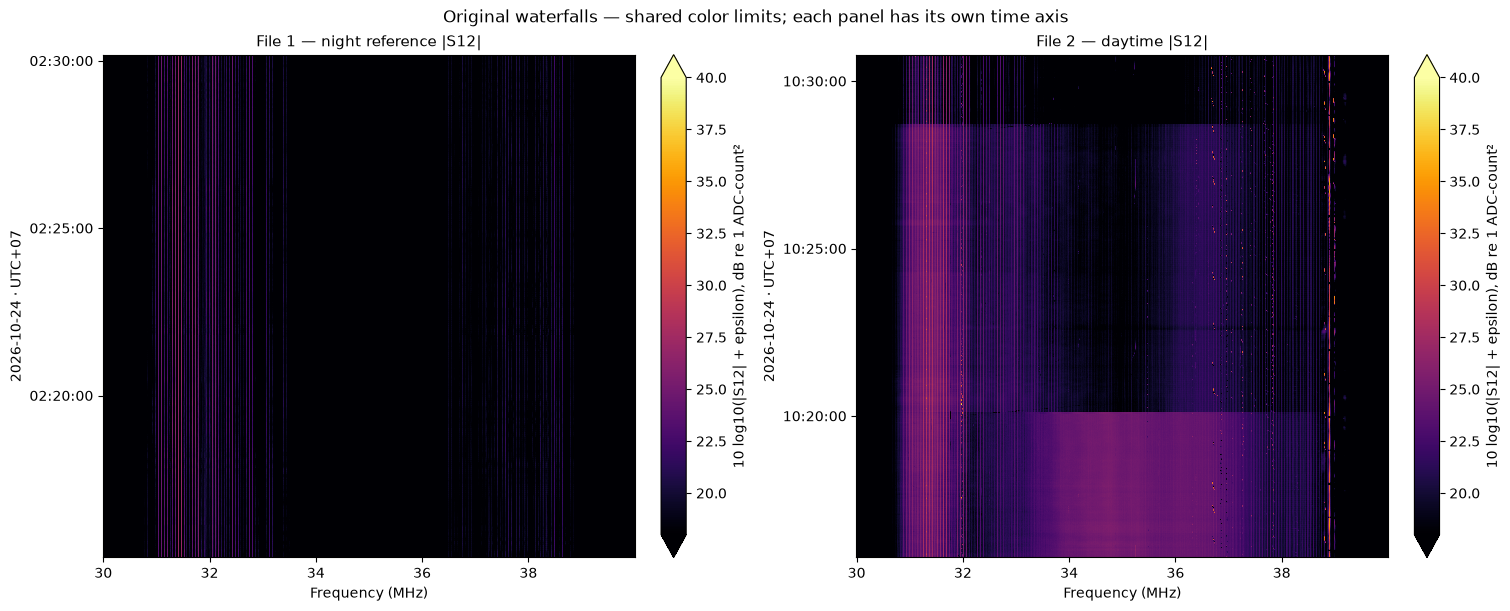

In [52]:
def finite_percentile(values, q):
    finite = np.asarray(values)[np.isfinite(values)]
    if not finite.size:
        raise ValueError("Không còn dữ liệu hữu hạn để vẽ.")
    return np.percentile(finite, q)

def plot_waterfall(ax, obs, values, title, cmap, norm=None, vmin=None, vmax=None):
    f = obs["frequency_hz"]
    half = obs["bandwidth_hz"] / 2
    freq_edges = np.r_[f - half, f[-1] + half] / 1e6
    segment_starts = np.flatnonzero(obs["breaks"])
    segment_ends = np.r_[segment_starts[1:], len(values)]
    epoch = mdates.date2num(datetime(1970, 1, 1, tzinfo=timezone.utc))
    mesh = None
    for first, stop in zip(segment_starts, segment_ends):
        # UTC row-start boundaries plus last support end; no interpolation across gaps.
        time_edges = np.r_[obs["starts"][first:stop], obs["ends"][stop-1]] / 86400 + epoch
        kwargs = {"norm": norm} if norm is not None else {"vmin": vmin, "vmax": vmax}
        mesh = ax.pcolormesh(freq_edges, time_edges, values[first:stop], shading="flat",
                             cmap=cmap, rasterized=True, **kwargs)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel(datetime.fromtimestamp(obs["starts"][0], DISPLAY_TIMEZONE).strftime("%Y-%m-%d") + " · UTC+07")
    ax.yaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=7))
    ax.yaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S", tz=DISPLAY_TIMEZONE))
    ax.set_xlim(*(DISPLAY_FREQ_MHZ if DISPLAY_FREQ_MHZ is not None else (freq_edges[0], freq_edges[-1])))
    return mesh

# Hai ảnh gốc dùng chung thang màu để so sánh mức tín hiệu.
lo, hi = RAW_VMIN_DB, RAW_VMAX_DB
fig_raw, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
for ax, obs, values, title in zip(axes, (night, day), (night_db, day_db),
                                  ("File 1 — night reference |S12|", "File 2 — daytime |S12|")):
    mesh = plot_waterfall(ax, obs, values, title, WATERFALL_CMAP, vmin=lo, vmax=hi)
    fig_raw.colorbar(mesh, ax=ax, label="10 log10(|S12| + epsilon), dB re 1 ADC-count²", extend="both")
fig_raw.suptitle("Original waterfalls — shared color limits; each panel has its own time axis")
plt.show()


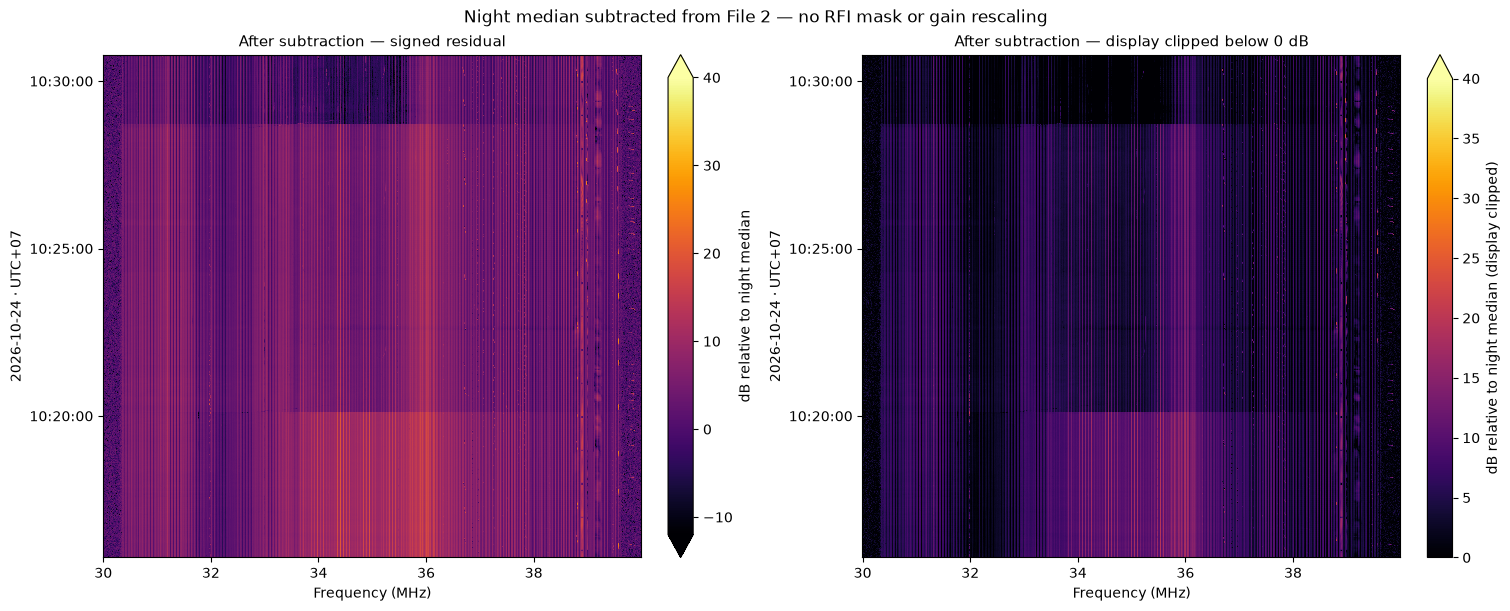

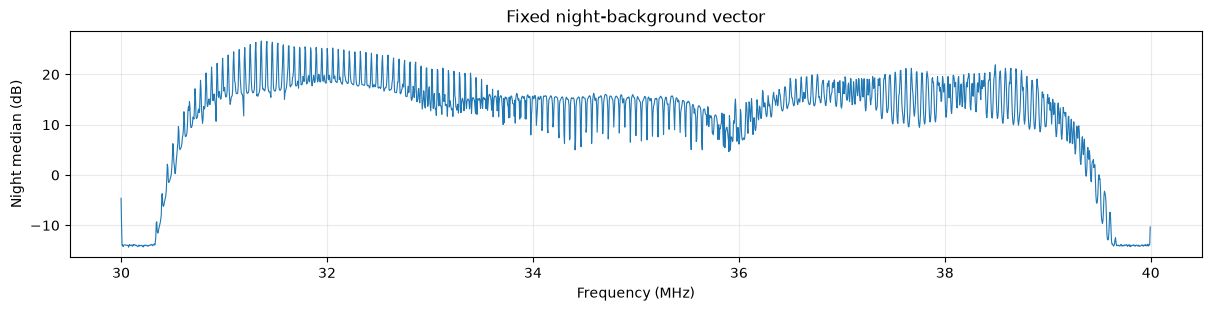

In [53]:
# Tính giới hạn từ dữ liệu chỉ để tô màu; không cắt hay thay đổi residual_db.
fig_result, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
mesh = plot_waterfall(axes[0], day, residual_db, "After subtraction — signed residual", WATERFALL_CMAP,
                      vmin=SIGNED_VMIN_DB, vmax=SIGNED_VMAX_DB)
fig_result.colorbar(mesh, ax=axes[0], label="dB relative to night median", extend="both")
mesh = plot_waterfall(axes[1], day, residual_display_db, "After subtraction — display clipped below 0 dB", WATERFALL_CMAP,
                      vmin=RESIDUAL_VMIN_DB, vmax=RESIDUAL_VMAX_DB)
fig_result.colorbar(mesh, ax=axes[1], label="dB relative to night median (display clipped)", extend="max")
fig_result.suptitle("Night median subtracted from File 2 — no RFI mask or gain rescaling")
plt.show()

# Nền đêm để kiểm tra các vạch nào đang được dùng làm reference.
fig_background, ax = plt.subplots(figsize=(12, 3), layout="constrained")
ax.plot(night["frequency_hz"] / 1e6, night_background_db, linewidth=.8)
ax.set(xlabel="Frequency (MHz)", ylabel="Night median (dB)", title="Fixed night-background vector")
ax.grid(alpha=.25)
plt.show()

if SAVE_PNG:
    fig_raw.savefig(PNG_PATH.with_name(PNG_PATH.stem + "_originals.png"), dpi=180)
    fig_result.savefig(PNG_PATH, dpi=180)
    print("Đã lưu PNG:", PNG_PATH.resolve())


## Đối chiếu phép tính

Các kiểm tra dưới đây kiểm tra công thức và việc giữ dấu; chúng không xác nhận phần dư là tín hiệu Mặt Trời sạch. Nhiễu đổi cường độ hoặc trôi giữa đêm và ngày vẫn có thể để lại vạch.

Mảng kết quả dùng tiếp: `residual_db` (signed), `residual_display_db` (cắt dưới 0 để vẽ), `night_background_db` (nền đêm từng bin). Dữ liệu H5 đầu vào không thay đổi.


In [54]:
np.testing.assert_allclose(residual_db, day_db - night_background_db[None, :], rtol=0, atol=0, equal_nan=True)
np.testing.assert_allclose(residual_display_db, np.maximum(residual_db, 0), rtol=0, atol=0, equal_nan=True)
assert np.isnan(residual_db[:, night_valid_count == 0]).all()

# Minh họa tại tần số có trong file (gần 38.901367 MHz nếu dải bao gồm điểm này).
requested_hz = 38.9013671875e6
bin_index = int(np.argmin(np.abs(day["frequency_hz"] - requested_hz)))
finite_rows = np.flatnonzero(np.isfinite(residual_db[:, bin_index]))
if finite_rows.size:
    row = int(finite_rows[0])
    print(f"Bin {bin_index}, {day['frequency_hz'][bin_index]/1e6:.9f} MHz:")
    print(f"  {day_db[row,bin_index]:.6f} − {night_background_db[bin_index]:.6f} = {residual_db[row,bin_index]:.6f} dB")
print("Kiểm tra công thức: PASS")


Bin 1823, 38.901367188 MHz:
  32.051780 − 17.732907 = 14.318873 dB
Kiểm tra công thức: PASS
